# Scanning SQUID: measured flux to a full planar vector current

This active review reconstructs the supplied **real**151×201lock-in flux image and independent dipole calibration through local Fourier Biot–Savart mathematics. Current truth is unavailable. Corrected original-method reference, untouched original complex output and fresh measurements are distinct.

The experiment used approximately600Hz,1microampere AC drive and1umheight. Magnetic-image pitch is1.2924×1.144um; the independent209²calibration has unknown dipole moment. Its actual source zero-pad/spline coarse kernel is supplied, with physical pitch1.295272×1.147336667um. We preserve that0.22–0.29%index-kernel approximation, rather than claim perfect physical registration. No target-derived calibration or normalization is introduced.

## Physics, sign, boundary and inverse

For negative-exponent forward FFT, the explicit preserved author effective transfer is
\[\hat f=\frac{\mu_0}{2i}e^{-Kh}P(k)\frac{k_x\hat J_y-k_y\hat J_x}{K},\qquad k_x\hat J_x+k_y\hat J_y=0.\]
Here f is numeric flux response,P the unnormalized signed coarse kernel FFT,h the height,K the angular radial frequency,and J the two relative-current components. Absolute moment, unit conversion and lock-in polarity are uncalibrated: J is signed **a.u.**, not A/m. Standard right-hand +Bz with this FFT has the opposite sign; we retain the explicitly declared author response orientation without fitting a sign.

Extend flux with the source linear_ramp-to-zero boundary100columns/75rows, then use a301×401periodic field. The extended area is an assumption, not measured current. Both full components are returned; observed-window cropping is only for display. Uniform current is invisible: the K=0bin of each component is set to zero.

The radial Hanning window H=(1+cos(pi*K/Kc))/2inside Kc=sqrt(kx_max²+ky_max²),zero outside, suppresses amplified high-frequency noise. Compute factor=2i*fhat*H/(mu0*exp(−Kh)*K*P), then Jxhat=−ky*factor and Jyhat=kx*factor. This is a closed-form inverse with no training or fabricated iteration.

## Investigated discrete corrections

The untouched modern source forces odd image sizes but assigns linspace frequencies offset by half a bin. An analytic plane wave exposes this mismatch. A centered odd delta PSF also exposes a one-pixel fftshift/ifftshift origin difference. Correcting both requires an explicit zero-mode convention; crop.real must not silently hide a non-Hermitian field. The archived untouched run, three minimally corrected original runs and independent repeat predate local extraction. We use exact FFT bins,ifftshift-centered PSF and DC0, then assert a negligible imaginary norm. These are disclosed corrections, not unchanged reproduction.

The full1989paper was read from its migrated12-page Vanderbilt institution PDF (original URL returned404). Its Eq6uses the positive-exponent transform, Eq10/11give field/continuity, Eq18the Hanning window. Its simulated loop/noise/coil/height experiments are historical motivation, not falsely presented as this real-data validation. Fresh cutoff/height/sensor/boundary sensitivity below retains the selected method's relevant comparisons without inventing current truth.

In [1]:
%matplotlib inline
from pathlib import Path
import sys,os,time,json,importlib.util
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
root=Path.cwd()
if root.name=='notebooks':root=root.parent
sys.path.insert(0,str(root))
from src.preprocessing import load_data
from src.visualization import run_experiments,make_figures,export
data=load_data(root/'data/raw_data.npz')
references=[]
for cutoff in [.5,1.,1.5]:
    with np.load(root/f'notebooks/reference_outputs/corrected_{cutoff:g}.npz',allow_pickle=False) as f:references.append(f['reconstruction'][0].copy())
with np.load(root/'notebooks/reference_outputs/unmodified_original.npz',allow_pickle=False) as f:unmodified={k:f[k].copy() for k in f.files}
start=time.perf_counter()
experiments=run_experiments(data,references,unmodified)
print('Actual complete fresh experiment runtime (s)',time.perf_counter()-start)
print(json.dumps(experiments['metrics'],indent=2))
print('Fresh table columns: cutoff,NCC_Jx,NCC_Jy,relativeL2_Jx,relativeL2_Jy,runtime_s')
print(experiments['table'])
print('Untouched source frequency-grid DC mismatch:',unmodified['legacy_kx'][150,200],unmodified['legacy_ky'][150,200])

Actual complete fresh experiment runtime (s) 1.0030575999990106
{
  "ncc_jx": 0.9999999999999999,
  "relative_l2_jx": 0.0,
  "ncc_jy": 0.9999999999999999,
  "relative_l2_jy": 0.0,
  "filtered_forward_residual": 4.1918793570890797e-16,
  "divergence_ratio": 6.8817977567313165e-15,
  "dc_ratio": 4.034877328568205e-18,
  "imaginary_ratio": 8.543366540737229e-16,
  "unmodified_imaginary_ratio_jx": 0.36005503696306407,
  "unmodified_imaginary_ratio_jy": 0.22321780000506614,
  "unmodified_real_filtered_forward_residual": 0.14181706413143685,
  "unmodified_real_divergence_ratio": 0.01239514062190711,
  "constant_boundary_relative_difference": 0.5057792221082194,
  "total_fresh_experiment_seconds": 1.002574199999799
}
Fresh table columns: cutoff,NCC_Jx,NCC_Jy,relativeL2_Jx,relativeL2_Jy,runtime_s
[[0.5       1.        1.        0.        0.        0.1076525]
 [1.        1.        1.        0.        0.        0.1074957]
 [1.5       1.        1.        0.        0.        0.1060445]]
Untouched 

## Independent strict evaluation of the fresh nominal field

Both signed components must agree separately with the repeated corrected-method reference; no actual truth is claimed. Each cosine must be at least0.99999999and relative L2 discrepancy at most1e−8, finite numerical tolerances fixed before local source. In addition, the full-field forward must match the **filtered,DC-removed**observation, divergence must vanish and means must be zero. Comparing directly to raw unfiltered flux would conflate regularization attenuation with solver error. The Judge implements its own operator and imports no solver. No fitted normalization, sign, phase, crop or spatial alignment enters any score.

In [2]:
prediction_path=Path(os.environ.get('IMAGING_REVIEW_PREDICTION',str(root/'output/reconstruction.npz')))
np.savez_compressed(prediction_path,reconstruction=experiments['currents'][1][None].astype('float64'))
spec=importlib.util.spec_from_file_location('independent_judge',root/'evaluation/judge.py')
judge=importlib.util.module_from_spec(spec);spec.loader.exec_module(judge)
report,code=judge.evaluate(prediction_path)
assert code==0,report
Path(os.environ.get('IMAGING_REVIEW_REPORT',str(root/'output/judge_report.json'))).write_text(json.dumps(report,indent=2),encoding='utf8')
print(json.dumps(report,indent=2))
np.savez_compressed(root/'notebooks/reference_outputs/cleaned_measurements.npz',parameter_table=experiments['table'],**{k:np.asarray(v) for k,v in experiments['metrics'].items()})
with np.load(root/'notebooks/reference_outputs/cleaned_measurements.npz',allow_pickle=False) as f:print('Separately archived fresh measurement keys',f.files)

{
  "status": "pass",
  "passed": true,
  "metrics": {
    "ncc_jx": 0.9999999999999999,
    "relative_l2_jx": 0.0,
    "ncc_jy": 0.9999999999999999,
    "relative_l2_jy": 0.0,
    "filtered_forward_residual": 4.1918793570890797e-16,
    "divergence_ratio": 6.8817977567313165e-15,
    "dc_ratio": 4.034877328568205e-18
  },
  "thresholds": {
    "ncc_jx": {
      "comparison": ">=",
      "boundary": 0.99999999
    },
    "relative_l2_jx": {
      "comparison": "<=",
      "boundary": 1e-08
    },
    "ncc_jy": {
      "comparison": ">=",
      "boundary": 0.99999999
    },
    "relative_l2_jy": {
      "comparison": "<=",
      "boundary": 1e-08
    },
    "filtered_forward_residual": {
      "comparison": "<=",
      "boundary": 1e-08
    },
    "divergence_ratio": {
      "comparison": "<=",
      "boundary": 1e-08
    },
    "dc_ratio": {
      "comparison": "<=",
      "boundary": 1e-10
    }
  },
  "errors": []
}


Separately archived fresh measurement keys ['parameter_table', 'ncc_jx', 'relative_l2_jx', 'ncc_jy', 'relative_l2_jy', 'filtered_forward_residual', 'divergence_ratio', 'dc_ratio', 'imaginary_ratio', 'unmodified_imaginary_ratio_jx', 'unmodified_imaginary_ratio_jy', 'unmodified_real_filtered_forward_residual', 'unmodified_real_divergence_ratio', 'constant_boundary_relative_difference', 'total_fresh_experiment_seconds']


## Five computed scientific figure groups

1. Real observations, independent calibration, original coarse index kernel, assumed extension and spectral window.
2. Both full corrected components; untouched real and discarded imaginary fields; differences and observed-window vectors. The untouched output was reproduced from the unmodified oracle in this batch, and is not true current.
3. Three actively reconstructed cutoff settings with common signed scales. Increased bandwidth changes noise/detail, without independent truth to select an optimum.
4. Fresh full-field forward versus filtered/DC0target, physical residual, raw/filtered profiles, divergence and untouched/corrected diagnostics.
5. Fresh height sensitivity, response/window, identity-PSF and boundary ablations. Height cases are assumptions applied to the same measurement, not new acquired heights. Individually normalized shape profiles are labeled display-only and never used for evaluation.

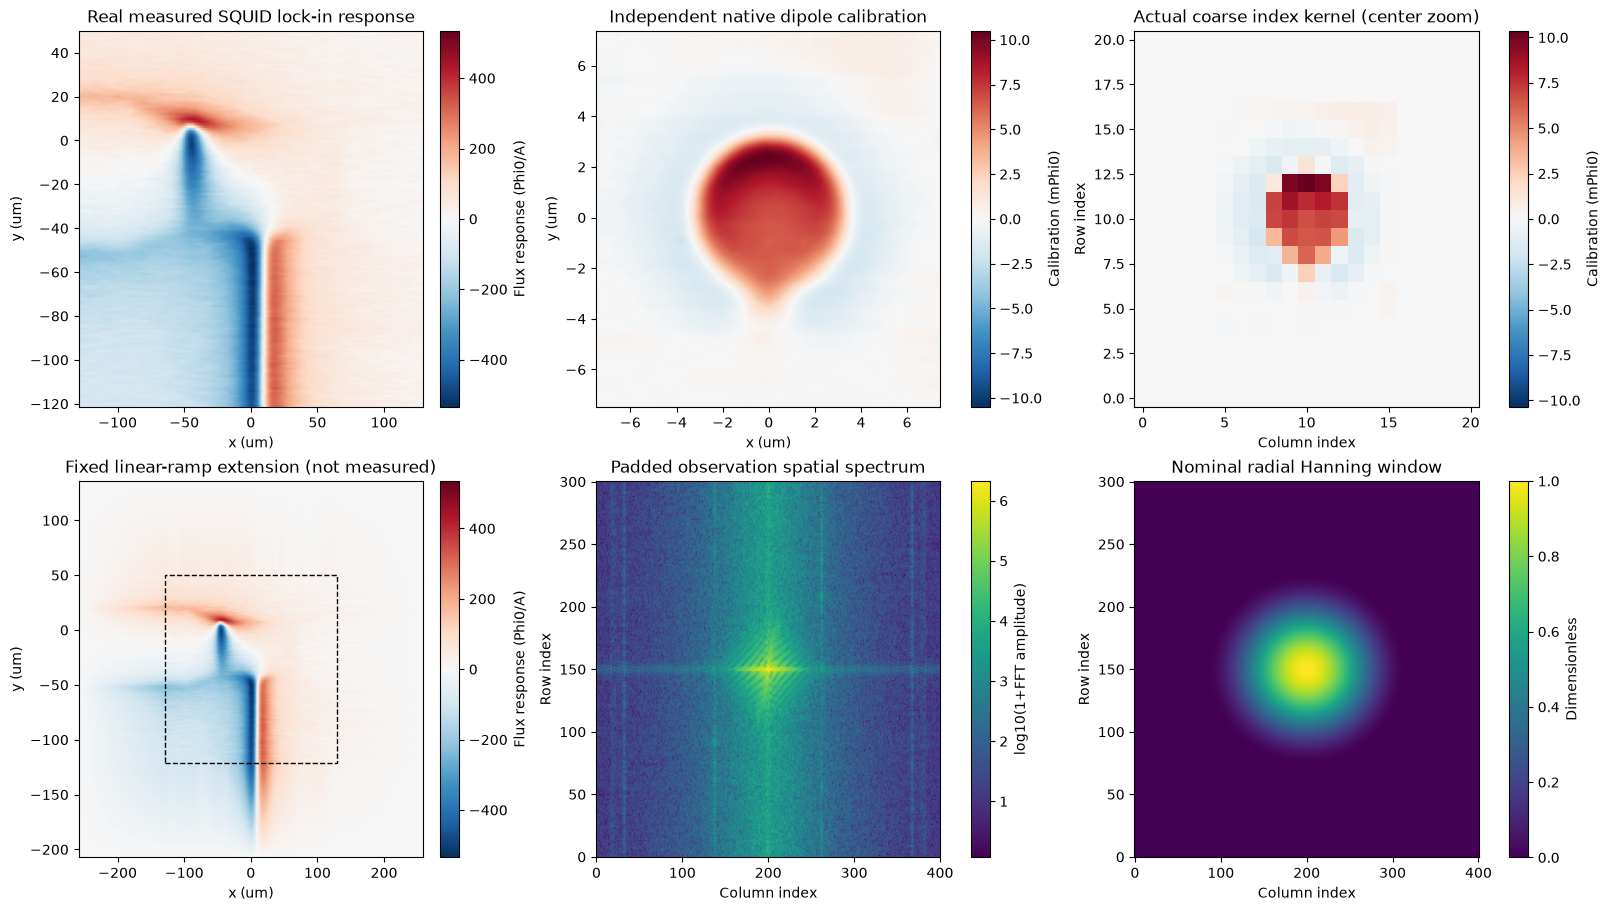

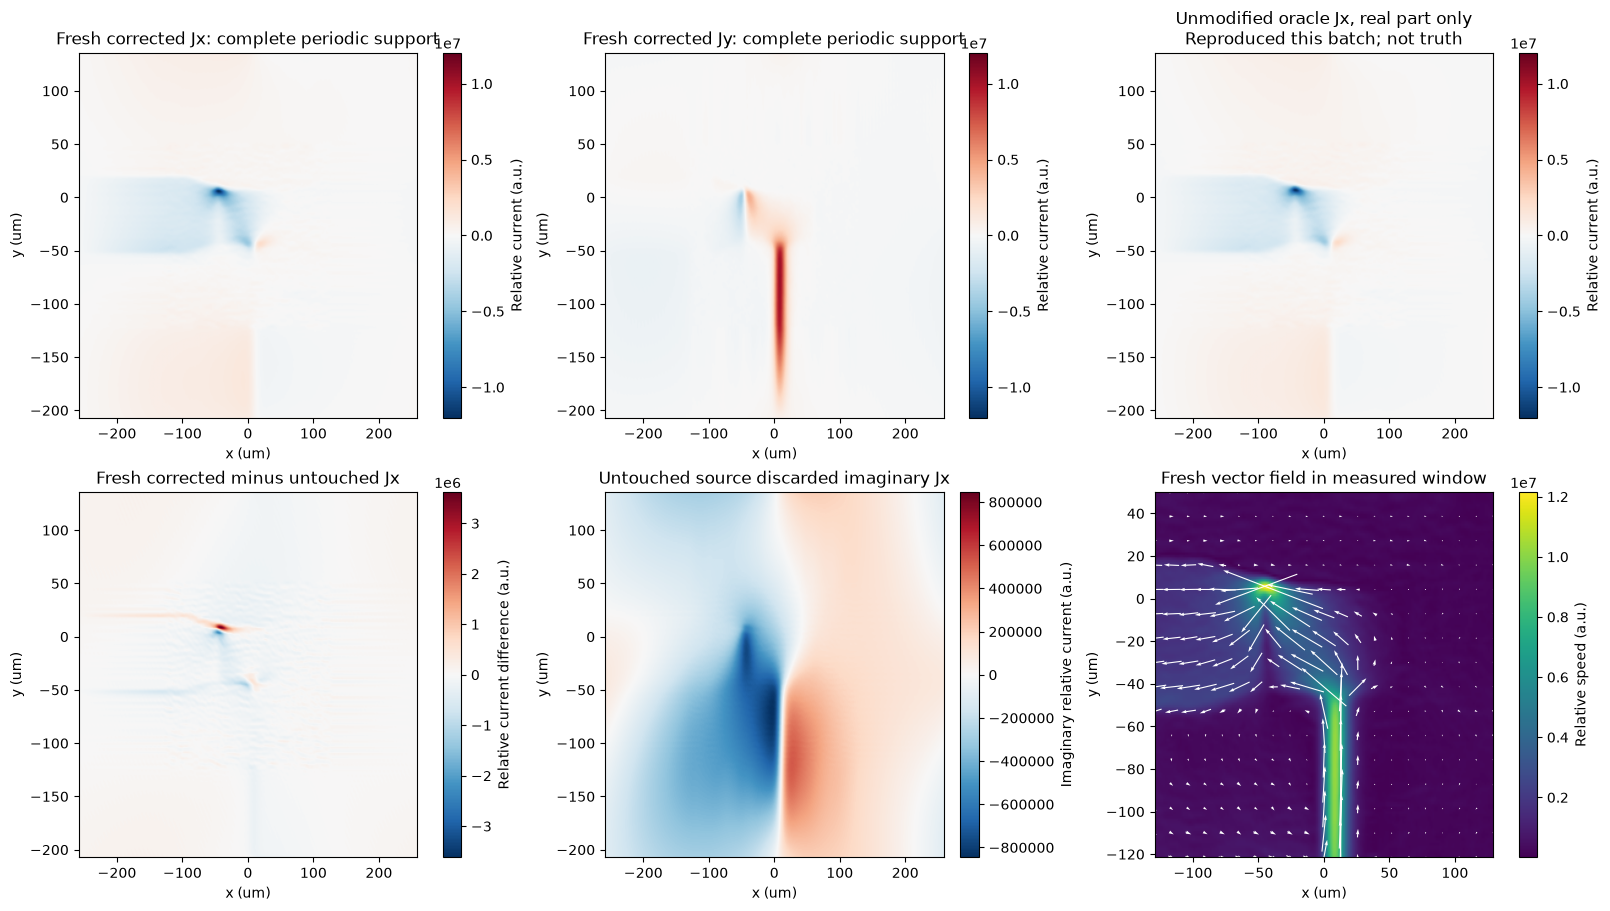

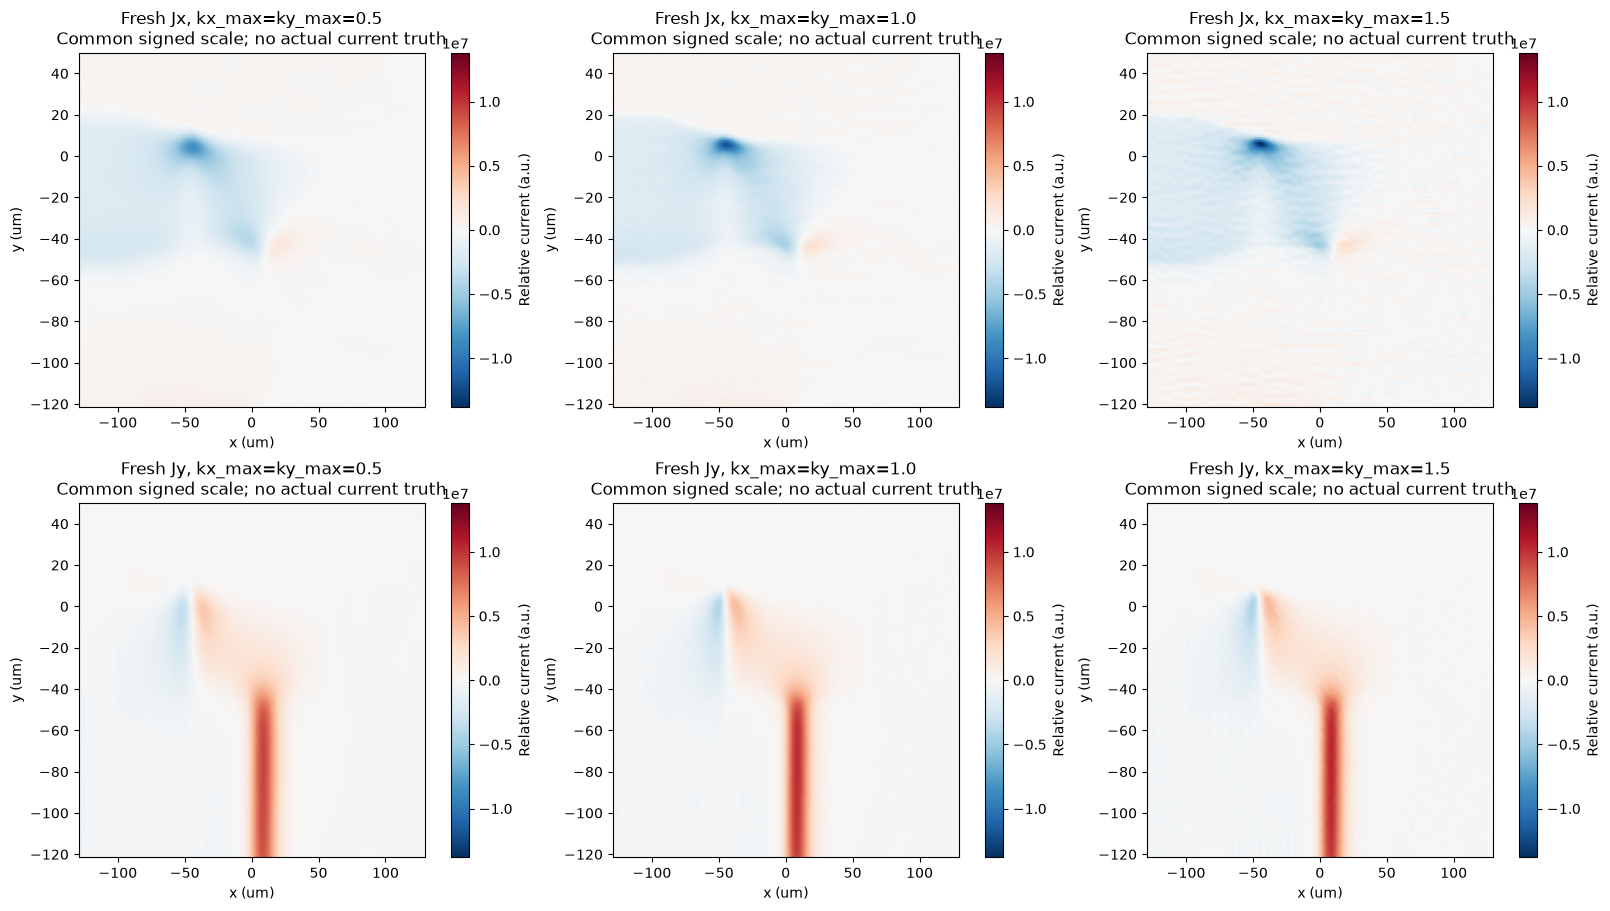

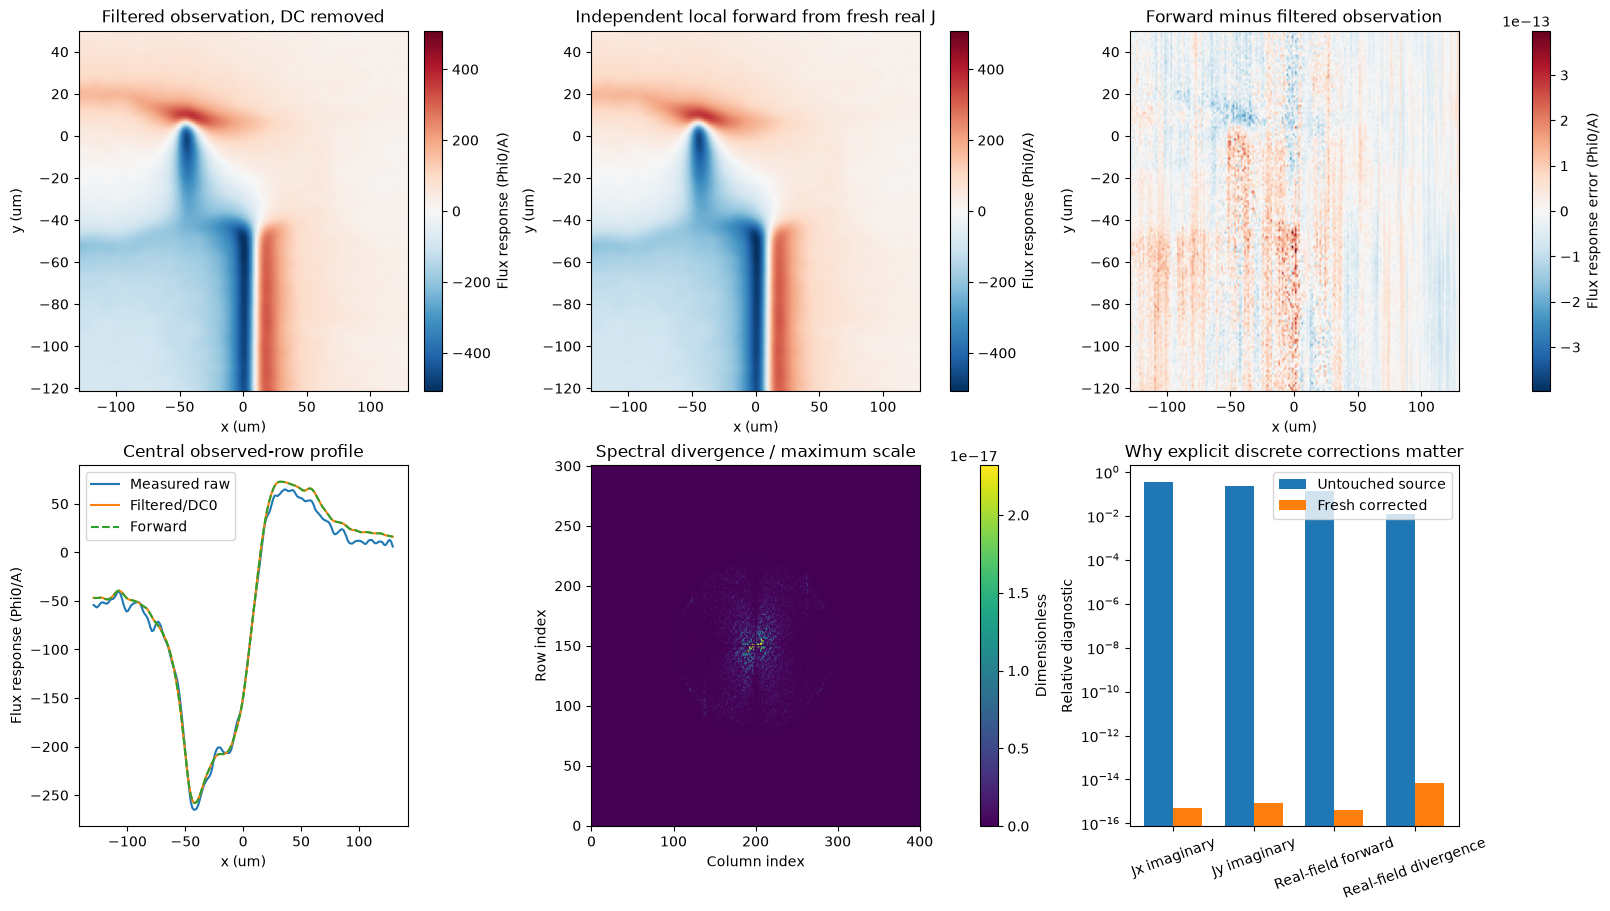

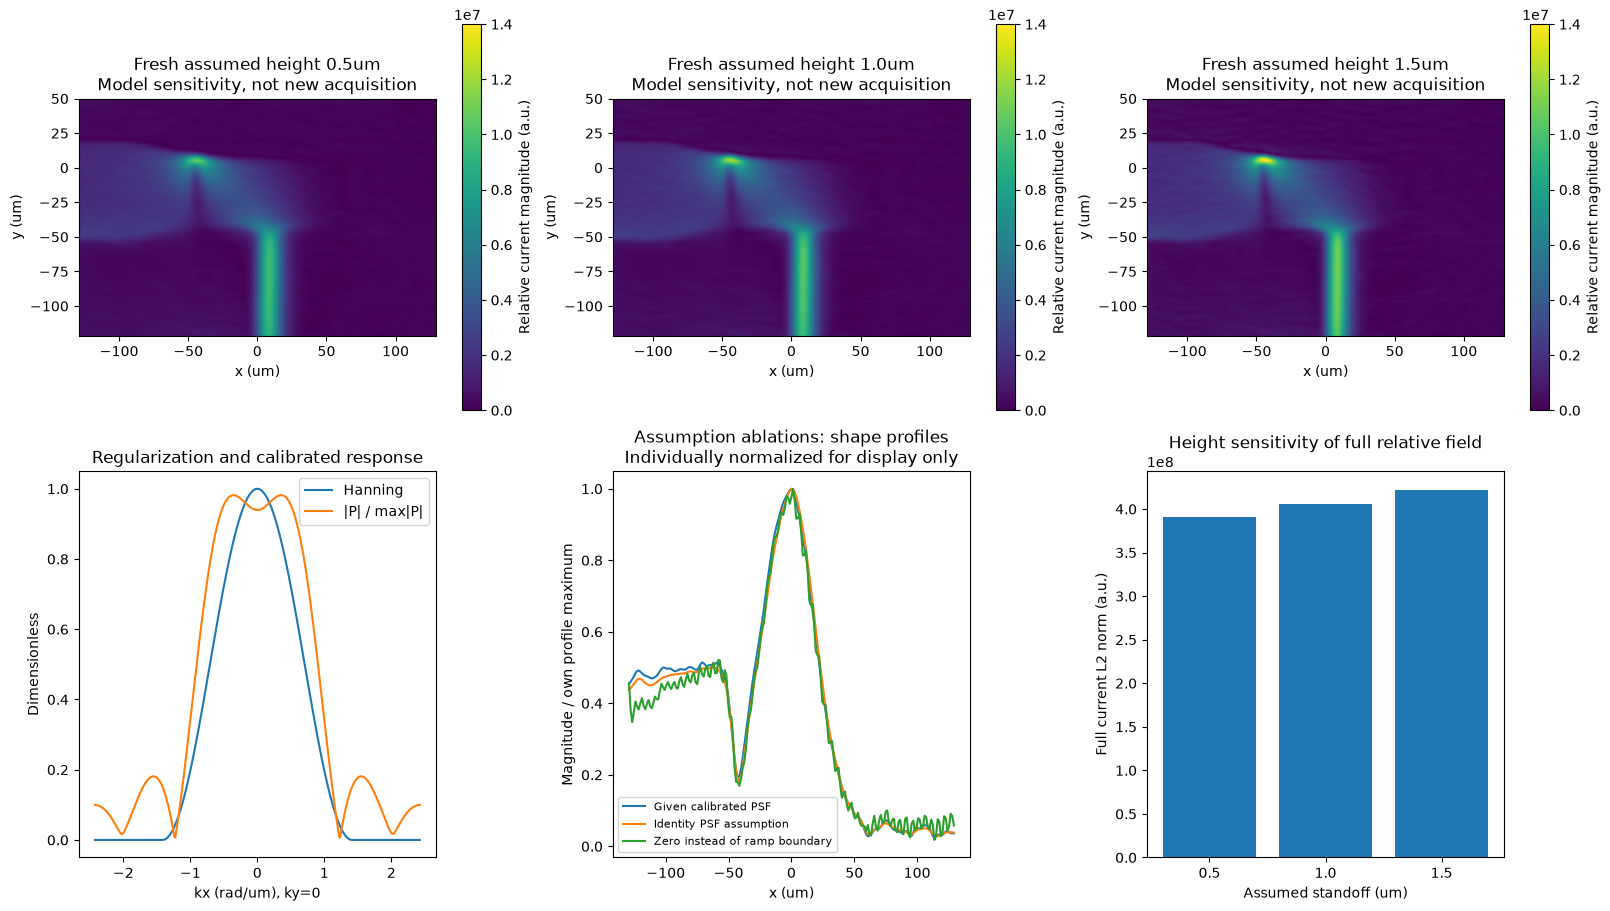

Private PNG/SVG/PDF and exact numeric exports completed.


In [3]:
figures=make_figures(data,experiments)
for figure in figures:
    display(figure)
    plt.close(figure)
directory=os.environ.get('IMAGING_REVIEW_EXPORT')
if directory:
    export(figures,data,experiments,Path(directory))
    print('Private PNG/SVG/PDF and exact numeric exports completed.')

## Interpretation and limitations

This measured-data inverse establishes local extraction, corrected-original numerical agreement and closed physical constraints under the declared discrete model. It does not establish absolute current amplitude/polarity, true off-image current, unique high-frequency detail, exact sensor geometry, or3Dcurrent. The full continuation depends on boundary assumptions; the zero mode is a gauge; existing coarse-calibration pitch and dipole-model limitations remain. No actual current ground truth was supplied or invented. Every fresh plotted method above was computed locally, and the unmodified archive is labeled separately.

References: Roth,Sepulveda,Wikswo,Journal of Applied Physics65,361–372(1989),doi10.1063/1.342549; modern Logan Bishop-Van Horn MIT source revision443b3a1c8efa3f9a37c1be5ce01e2e2da84d0aa0. Full hashes, exact source URLs, corrections, licenses and function/equation tests are maintained in test/validation.md.